<a href="https://colab.research.google.com/github/muhozam/battery-cycle-life/blob/main/Prediction_battery_cyclelife_before_capacity_degradation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Data-Driven Prediction of Battery Cycle Life

This notebook implements and expands the data-driven predictive modeling pipeline described in the landmark paper:
**"Data-driven prediction of battery cycle life before capacity degradation"** by *Peter M. Severson, Kristin A. Attia, Norman Jin, Nicholas Perkins, Bryan Dawson, Benben Liao, Louise Olsson, Michael H. Kesler, Steven M. Savage, Stefan Westerhoff, François M. Apitz, Jörg Schmalstieg, William C. Chueh & Richard D. Braatz* (*Nature Energy*, 2019).

### Notebook Objectives & Accomplishments
This pipeline models and predicts the ultimate cycle life of lithium-ion batteries using operational data from only the **first 100 cycles**—well before noticeable capacity degradation begins. The workflow covers:
1. **Data Ingestion & Cleaning**: Parsing and consolidating ~9 GB of raw MATLAB HDF5 (`-v7.3`) experimental batches spanning 124 commercial A123 Systems LFP/graphite cylindrical cells (nominal 1.1 Ah capacity, 3.3V nominal) cycled under extreme fast-charging conditions (up to 6C CC-CV charging, 4C discharging) at 30°C.
2. **Feature Engineering**: Recreating the paper's 22 nested features, most notably extracting the log-variance of the differential capacity curve ($|\Delta Q_{100-10}(V)|$) as a physical signature of early thermodynamic and kinetic deterioration.
3. **Multivariate Modeling**: Evaluating classical regularized machine learning (Elastic-Net) alongside modern deep learning frameworks (Conv1D and Dense Neural Networks) on a stratified train/test split to assess generalization and explore physical vs. automated curve-based feature extraction.
4. **Uncertainty Quantification**: Implementing Monte Carlo dropout on neural network architectures to provide statistical confidence intervals ($\pm2\sigma$) for safety-critical diagnostics.

### Key Experimental & Instrument Details
* **Primary Predictor ($|\Delta Q_{100-10}(V)|$)**: Captures cell-to-cell differences in electrochemical degradation pathways (e.g., loss of active material and lithium inventory) before the onset of capacity fade.
* **Internal Resistance (IR)**: Measured at 80% state-of-charge (SOC) by averaging 10 pulses of $\pm3.6$C with a 30 ms pulse width.
* **Temperature**: Monitored using external thermocouples (subject to occasional contact issues, addressed via Hampel filtering and robust interpolation in the cleaning step).

In [37]:
# ── 1. Imports (grouped by purpose)
# Standard library
from pathlib import Path

# Data download & raw file I/O
import requests
from tqdm.auto import tqdm
import h5py

# Numerics & data wrangling
import numpy as np
import pandas as pd
from scipy import stats
from scipy.integrate import trapezoid

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Classical ML (scikit-learn)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import ElasticNetCV
from sklearn.metrics import root_mean_squared_error, mean_absolute_percentage_error

# Deep learning
import tensorflow as tf
from tensorflow import keras

# Colab
from google.colab import drive

In [38]:
# ── 2. Configuration: Drive paths, data URLs, constants, known dataset fixes

try:
    from google.colab import drive
    drive.mount("/content/drive")
    DATA_DIR = Path("/content/drive/MyDrive/battery_data")
except ImportError:
    DATA_DIR = Path("./battery_data")  # fallback for local development
SEED = 42
RAW_DIR       = DATA_DIR / "raw"            # .mat files (~3 GB each)
PROCESSED_DIR = DATA_DIR / "processed"
for folder in (RAW_DIR, PROCESSED_DIR):
    folder.mkdir(parents=True, exist_ok=True)
CYCLES_FILE  = PROCESSED_DIR / "cycles_clean.parquet"   # per-cycle table, cleaned
DELTA_Q_FILE = PROCESSED_DIR / "delta_q.npz"            # ΔQ_100-10(V) curve per cell

BATCH_URLS = {
    "2017-05-12": "https://data.matr.io/1/api/v1/file/5c86c0b5fa2ede00015ddf66/download",
    "2017-06-30": "https://data.matr.io/1/api/v1/file/5c86bf13fa2ede00015ddd82/download",
    "2018-04-12": "https://data.matr.io/1/api/v1/file/5c86bd64fa2ede00015ddbb2/download",
}
SUMMARY_FIELDS = ["cycle", "QDischarge", "QCharge", "IR", "Tavg", "Tmin", "Tmax", "chargetime"]
VOLTAGE_GRID = np.linspace(3.6, 2.0, 1000)    # Qdlin voltage axis
EARLY_CYCLE, LATE_CYCLE = 10, 100             # ΔQ = Q(cycle 100) − Q(cycle 10)

# Severson et al. fixes: batch-2 cells that continue batch-1 cells -> (parent, cycles run in batch 2)
CONTINUATION_TO_PARENT = {
    "b_2017_06_30_c7":  ("b_2017_05_12_c0", 662),
    "b_2017_06_30_c8":  ("b_2017_05_12_c1", 981),
    "b_2017_06_30_c9":  ("b_2017_05_12_c2", 1060),
    "b_2017_06_30_c15": ("b_2017_05_12_c3", 208),
    "b_2017_06_30_c16": ("b_2017_05_12_c4", 482),
}
# Never reached 80% SOH (batch 1) or noisy channels (batch 3)
EXCLUDED_CELLS = {f"b_2017_05_12_c{i}" for i in (8, 10, 12, 13, 22)} | \
                 {f"b_2018_04_12_c{i}" for i in (2, 23, 32, 37, 42, 43)}

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [39]:
# ── 3. Download raw batches (skips files already on Drive)
def download_batch(batch_date, url):
    mat_path = RAW_DIR / f"batch_{batch_date}.mat"
    if mat_path.exists() and mat_path.stat().st_size > 0:
        print("exists:", mat_path.name)
        return mat_path
    partial_path = mat_path.with_suffix(".part")          # avoids half-written .mat on failure
    with requests.get(url, stream=True, timeout=60) as response:
        response.raise_for_status()
        total_bytes = int(response.headers.get("Content-Length", 0))
        with open(partial_path, "wb") as out_file, \
             tqdm(total=total_bytes, unit="B", unit_scale=True, desc=batch_date) as progress:
            for chunk in response.iter_content(1 << 20):  # 1 MB chunks
                out_file.write(chunk)
                progress.update(len(chunk))
    partial_path.rename(mat_path)
    return mat_path

mat_paths = {batch_date: download_batch(batch_date, url) for batch_date, url in BATCH_URLS.items()}

exists: batch_2017-05-12.mat
exists: batch_2017-06-30.mat
exists: batch_2018-04-12.mat


In [40]:
# ── 4. (Optional) Inspect structure of the raw .mat files
for batch_date, mat_path in mat_paths.items():
    with h5py.File(mat_path, "r") as mat:
        batch = mat["batch"]
        print(f"{batch_date}: {batch['summary'].shape[0]} cells | fields: {list(batch.keys())}")

2017-05-12: 46 cells | fields: ['Vdlin', 'barcode', 'channel_id', 'cycle_life', 'cycles', 'policy', 'policy_readable', 'summary']
2017-06-30: 48 cells | fields: ['Vdlin', 'barcode', 'channel_id', 'cycle_life', 'cycles', 'policy', 'policy_readable', 'summary']
2018-04-12: 46 cells | fields: ['Vdlin', 'barcode', 'channel_id', 'cycle_life', 'cycles', 'policy', 'policy_readable', 'summary']


In [41]:
# ── 5. HDF5 readers (MATLAB v7.3: every field is an object reference -> mat[ref][()])
def read_scalar(mat, ref):
    values = np.ravel(mat[ref][()])
    return float(values[0]) if values.size else np.nan

def read_string(mat, ref):
    """MATLAB char arrays are stored as uint16 character codes."""
    return "".join(map(chr, np.ravel(mat[ref][()])))

def qdlin_at_cycle(mat, qdlin_refs, cycle_numbers, cycle):
    """Qdlin curve (1000 pts) for one cycle NUMBER; NaNs if that cycle is missing."""
    rows = np.flatnonzero(cycle_numbers == cycle)
    if rows.size == 0 or rows[0] >= qdlin_refs.shape[0]:
        return np.full(VOLTAGE_GRID.size, np.nan, dtype="float32")
    return np.ravel(mat[qdlin_refs[rows[0], 0]][()]).astype("float32")

def read_batch(mat_path, batch_date):
    """ONE pass over a .mat file -> (per-cycle DataFrame, {cell_id: ΔQ_100-10(V)})."""
    batch_prefix = f"b_{batch_date.replace('-', '_')}"
    cycle_frames, delta_q_curves = [], {}
    with h5py.File(mat_path, "r") as mat:
        batch = mat["batch"]
        for cell_idx in range(batch["summary"].shape[0]):
            cell_id = f"{batch_prefix}_c{cell_idx}"
            if cell_id in EXCLUDED_CELLS:
                continue
            summary = mat[batch["summary"][cell_idx, 0]]
            cell_cycles = pd.DataFrame({field: np.ravel(summary[field][()]) for field in SUMMARY_FIELDS})
            cell_cycles["cell_id"] = cell_id
            cell_cycles["batch"] = batch_date
            cell_cycles["policy"] = read_string(mat, batch["policy_readable"][cell_idx, 0])
            cell_cycles["cycle_life"] = read_scalar(mat, batch["cycle_life"][cell_idx, 0])
            cycle_frames.append(cell_cycles)

            if cell_id in CONTINUATION_TO_PARENT:     # its first 100 cycles belong to the parent cell
                continue
            qdlin_refs = mat[batch["cycles"][cell_idx, 0]]["Qdlin"]
            cycle_numbers = cell_cycles["cycle"].to_numpy()
            delta_q_curves[cell_id] = (qdlin_at_cycle(mat, qdlin_refs, cycle_numbers, LATE_CYCLE)
                                       - qdlin_at_cycle(mat, qdlin_refs, cycle_numbers, EARLY_CYCLE))
    return pd.concat(cycle_frames, ignore_index=True), delta_q_curves



In [42]:
# ── 6. Parse all batches (summary + ΔQ in the same pass)
cycle_frames, delta_q_curves = [], {}
for batch_date, mat_path in mat_paths.items():
    batch_cycles, batch_delta_q = read_batch(mat_path, batch_date)
    cycle_frames.append(batch_cycles)
    delta_q_curves.update(batch_delta_q)
    print(f"{batch_date}: {batch_cycles.cell_id.nunique()} cells, {len(batch_cycles)} rows")
cycle_df = pd.concat(cycle_frames, ignore_index=True)

2017-05-12: 41 cells, 34341 rows
2017-06-30: 48 cells, 24920 rows
2018-04-12: 40 cells, 41240 rows


In [43]:
# ── 7. Dataset fixes + signal cleaning functions
def merge_continuations(cycle_df):
    """Append each batch-2 continuation to its batch-1 parent and correct the parent's cycle life."""
    for continuation_id, (parent_id, extra_cycles) in CONTINUATION_TO_PARENT.items():
        is_parent = cycle_df.cell_id == parent_id
        is_continuation = cycle_df.cell_id == continuation_id
        parent_life = cycle_df.loc[is_parent, "cycle_life"].iloc[0]
        cycle_df.loc[is_continuation, "cycle"] += cycle_df.loc[is_parent, "cycle"].max()
        cycle_df.loc[is_continuation, ["cell_id", "batch"]] = [parent_id, "2017-05-12"]
        cycle_df.loc[is_parent | is_continuation, "cycle_life"] = parent_life + extra_cycles
    return cycle_df

def hampel_filter(series, window=5, n_sigmas=3):
    """Replace points > n_sigmas robust SDs from the rolling median with that median."""
    rolling_median = series.rolling(window, center=True, min_periods=1).median()
    deviation = (series - rolling_median).abs()
    robust_sd = 1.4826 * deviation.rolling(window, center=True, min_periods=1).median()
    return series.where(deviation <= n_sigmas * robust_sd + 1e-9, rolling_median)

def clean_signals(cycle_df, columns=("QDischarge", "IR", "Tavg", "chargetime")):
    """IR = 0 and out-of-range capacity -> NaN, interpolate, then remove spikes per cell."""
    cycle_df["IR"] = cycle_df["IR"].replace(0, np.nan)
    cycle_df.loc[~cycle_df.QDischarge.between(0.8, 1.2), "QDischarge"] = np.nan   # nominal 1.1 Ah
    by_cell = cycle_df.groupby("cell_id")
    for column in columns:
        cycle_df[column] = by_cell[column].transform(
            lambda s: hampel_filter(s.interpolate(limit_direction="both")))
    return cycle_df

In [44]:
# ── 8. Apply fixes, shrink dtypes, save the ONLY two processed files
cycle_df = clean_signals(merge_continuations(cycle_df))
cycle_df = (cycle_df
            .astype({**{field: "float32" for field in SUMMARY_FIELDS[1:]},
                     "cycle": "int32", "cell_id": "category", "batch": "category", "policy": "category"})
            .sort_values(["cell_id", "cycle"]).reset_index(drop=True))
cycle_df.to_parquet(CYCLES_FILE, index=False)

dq_cell_ids = sorted(delta_q_curves)
np.savez_compressed(DELTA_Q_FILE, cell_id=dq_cell_ids, voltage=VOLTAGE_GRID,
                    delta_q=np.stack([delta_q_curves[c] for c in dq_cell_ids]))

assert cycle_df.cell_id.nunique() == len(delta_q_curves) == 124
print(f"{len(cycle_df)} rows, {cycle_df.memory_usage(deep=True).sum() / 1e6:.1f} MB in memory")

100501 rows, 4.3 MB in memory


In [45]:
# ── 9. Reload processed data (later sessions: run cells 1–2, then this; skip 3–8)
cycle_df = pd.read_parquet(CYCLES_FILE)
with np.load(DELTA_Q_FILE) as saved:
    delta_q_curves = dict(zip(saved["cell_id"], saved["delta_q"]))
print(cycle_df.cell_id.nunique(), "cells |", len(delta_q_curves), "ΔQ curves")

124 cells | 124 ΔQ curves


In [46]:
# ── 10. EDA: one row per cell + cycle-life statistics (on CLEANED data)
cell_df = (cycle_df.groupby("cell_id", observed=True)
                   .agg(batch=("batch", "first"), policy=("policy", "first"),
                        cycle_life=("cycle_life", "first"), last_cycle=("cycle", "max"))
                   .reset_index())

life_stats = pd.concat([cell_df.groupby("batch", observed=True).cycle_life.describe(),
                        cell_df.cycle_life.describe().rename("ALL").to_frame().T])
life_stats = life_stats.assign(IQR=life_stats["75%"] - life_stats["25%"],
                               CV_pct=100 * life_stats["std"] / life_stats["mean"],
                               max_min_ratio=life_stats["max"] / life_stats["min"])
display(life_stats.round(1))
display(cell_df.groupby("policy", observed=True).cycle_life.describe()
               .sort_values("50%", ascending=False).head(10).round(0))
display(cell_df.sort_values("cycle_life").iloc[[0, 1, 2, -3, -2, -1]])   # extremes

,count,mean,std,min,25%,50%,75%,max,IQR,CV_pct,max_min_ratio
2017-05-12,41.0,921.3,400.8,534.0,702.0,842.0,966.0,2237.0,264.0,43.5,4.2
2017-06-30,43.0,473.2,76.8,148.0,461.0,481.0,499.0,713.0,38.0,16.2,4.8
2018-04-12,40.0,1032.0,308.6,541.0,827.2,964.5,1122.8,1935.0,295.5,29.9,3.6
ALL,124.0,801.6,379.7,148.0,498.8,736.5,946.5,2237.0,447.8,47.4,15.1


,count,mean,std,min,25%,50%,75%,max
policy,,,,,,,,
3.6C(80%)-3.6C,3.0,2083.0,204.0,1852.0,2006.0,2160.0,2198.0,2237.0
4.8C(80%)-4.8C-newstructure,4.0,1588.0,351.0,1078.0,1498.0,1720.0,1810.0,1836.0
4C(80%)-4C,2.0,1572.0,194.0,1434.0,1503.0,1572.0,1640.0,1709.0
4.4C(80%)-4.4C,1.0,1074.0,NaN,1074.0,1074.0,1074.0,1074.0,1074.0
5.4C(40%)-3.6C,1.0,1054.0,NaN,1054.0,1054.0,1054.0,1054.0,1054.0
5.3C(54%)-4C-newstructure,8.0,1074.0,130.0,935.0,977.0,1051.0,1156.0,1315.0
5.6C(19%)-4.6C-newstructure,7.0,963.0,149.0,796.0,816.0,1028.0,1070.0,1146.0
6C(30%)-3.6C,1.0,1014.0,NaN,1014.0,1014.0,1014.0,1014.0,1014.0
8C(15%)-3.6C,2.0,1008.0,60.0,966.0,987.0,1008.0,1030.0,1051.0


,cell_id,batch,policy,cycle_life,last_cycle
42,b_2017_06_30_c1,2017-06-30,2C(10%)-6C,148.0,170
41,b_2017_06_30_c0,2017-06-30,1C(4%)-6C,300.0,326
62,b_2017_06_30_c3,2017-06-30,2C(7%)-5.5C,335.0,361
112,b_2018_04_12_c38,2018-04-12,5C(67%)-4C-newstructure,1935.0,1934
1,b_2017_05_12_c1,2017-05-12,3.6C(80%)-3.6C,2160.0,2159
9,b_2017_05_12_c2,2017-05-12,3.6C(80%)-3.6C,2237.0,2236


### EDA Observations: Cycle Life Distribution by Batch

* **Batch Performance Disparity**: Cells from the **2017-06-30** batch exhibit a significantly depressed cycle-life distribution compared to the other two groups.
* **Low-Life Outliers**: Over $75\%$ of the cells in the 2017-06-30 batch fail before $500$ cycles ($75\%$ percentile is at $499$ cycles). This is strictly lower than the *minimum* observed lifetimes of the other two batches ($534$ cycles for 2017-05-12 and $541$ cycles for 2018-04-12).
* **High-Life Outliers**: The **2018-04-12** batch contains exceptionally long-lived cells (maximum of $1,935$ cycles), introducing a strong right-skew to the global lifetime distribution.

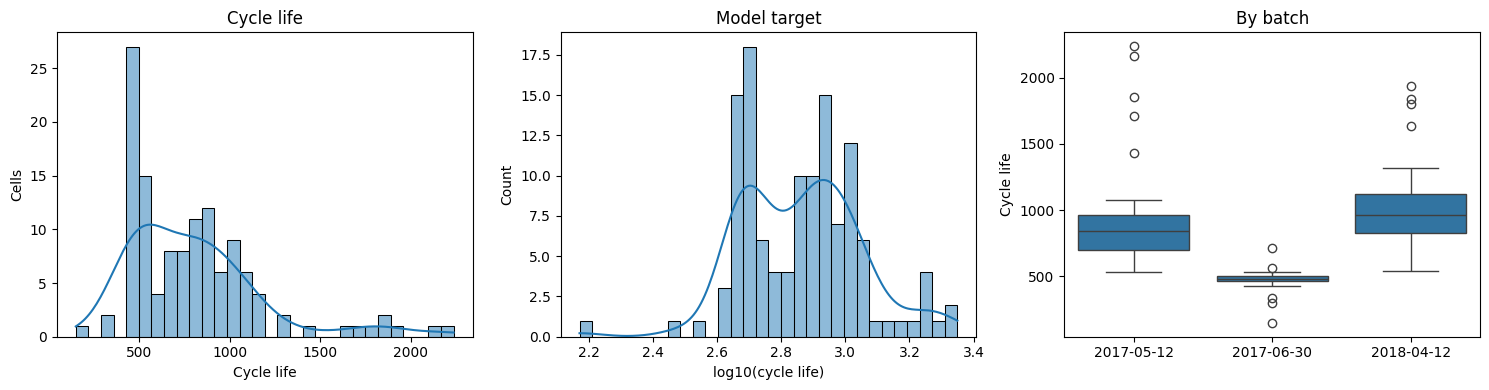

In [47]:
# ── 11. EDA plots: cycle life, log10 target, by batch
valid_cycle_life = cell_df.cycle_life.dropna()
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(valid_cycle_life, bins=30, kde=True, ax=axes[0])
axes[0].set(xlabel="Cycle life", ylabel="Cells", title="Cycle life")
sns.histplot(np.log10(valid_cycle_life), bins=30, kde=True, ax=axes[1])
axes[1].set(xlabel="log10(cycle life)", title="Model target")
sns.boxplot(data=cell_df, x="batch", y="cycle_life", ax=axes[2])
axes[2].set(title="By batch", xlabel="", ylabel="Cycle life")
plt.tight_layout(); plt.show()

##Observations



*   Bimodal distribution in the cycle life histogram plots. The dataset is slightly right-skewed.
*   The log10(lifecycle) plot heightens the bimodal distribution centered around 2.7 and about 2.9 (this having higher density).


*   The barplot shows that there outliers with cycle-life above 1750 in the batch 2018-04-12 which are the source of the right-skew in overall dataset.


*   There many outliers with very low cycle-life in the 2-17-06-30 batch which are the primary cause of the left-skew observed in log10(cycle life) plot.








In [48]:
# ── 12. Feature functions (Severson et al.)
def delta_q_features(delta_q):
    """log10|stat| of the ΔQ_100-10(V) curve. stats.describe gives var/min/skew/kurtosis in one call."""
    summary = stats.describe(delta_q[np.isfinite(delta_q)])
    return {"log_var_dQ":  np.log10(summary.variance),             # strongest single predictor
            "log_min_dQ":  np.log10(abs(summary.minmax[0])),      # largest local capacity loss
            "log_skew_dQ": np.log10(abs(summary.skewness)),
            "log_kurt_dQ": np.log10(abs(summary.kurtosis))}

def fade_line(capacity):
    """Linear capacity-fade fit vs cycle number -> (slope, intercept)."""
    capacity = capacity.dropna()
    fit = stats.linregress(capacity.index, capacity.values)
    return fit.slope, fit.intercept

def summary_features(cell_cycles):
    """Capacity, charge-time, temperature and IR features from cycles ≤ 100.
    Cycle 1 is skipped (formation/artefact cycle); 91–100 = most recent fade rate."""
    by_cycle = cell_cycles.drop_duplicates("cycle").set_index("cycle").sort_index()
    early, last_ten = by_cycle.loc[2:100], by_cycle.loc[91:100]
    cycle_2, cycle_100 = by_cycle.loc[2], by_cycle.loc[100]
    slope_early, icpt_early = fade_line(early.QDischarge)
    slope_last, icpt_last = fade_line(last_ten.QDischarge)
    return {
        "Qd_2": cycle_2.QDischarge,
        "Qd_max_minus_2": early.QDischarge.max() - cycle_2.QDischarge,
        "slope_2_100": slope_early, "icpt_2_100": icpt_early,
        "slope_91_100": slope_last, "icpt_91_100": icpt_last,
        "chargetime_avg_1_5": by_cycle.loc[1:5, "chargetime"].mean(),
        "T_max": early.Tmax.max(), "T_min": early.Tmin.min(),
        "T_int_2_100": trapezoid(early.Tavg, early.index),       # cumulative thermal exposure
        "IR_2": cycle_2.IR, "IR_min_2_100": early.IR.min(),
        "IR_100_minus_2": cycle_100.IR - cycle_2.IR,
    }

In [49]:
# ── 13. Feature sets (nested Severson models)
VARIANCE_FEATS  = ["log_var_dQ"]
DISCHARGE_FEATS = VARIANCE_FEATS + ["log_min_dQ", "log_skew_dQ", "log_kurt_dQ", "Qd_2", "Qd_max_minus_2"]
FULL_FEATS      = DISCHARGE_FEATS + ["slope_2_100", "icpt_2_100", "slope_91_100", "icpt_91_100",
                                     "chargetime_avg_1_5", "T_max", "T_min", "T_int_2_100",
                                     "IR_2", "IR_min_2_100", "IR_100_minus_2"]
FEATURE_SETS = {"variance": VARIANCE_FEATS, "discharge": DISCHARGE_FEATS, "full": FULL_FEATS}

In [50]:
# ── 14. Build feature table in memory (fast -> not saved)
early_cycles = cycle_df[cycle_df.cycle <= LATE_CYCLE]
feature_rows = []
for cell_id, cell_cycles in early_cycles.groupby("cell_id", observed=True):
    first_row = cell_cycles.iloc[0]
    feature_rows.append({"cell_id": cell_id, "batch": first_row.batch, "policy": first_row.policy,
                         "cycle_life": first_row.cycle_life,
                         **delta_q_features(delta_q_curves[cell_id]), **summary_features(cell_cycles)})
feature_df = pd.DataFrame(feature_rows)
feature_df["log_life"] = np.log10(feature_df.cycle_life)     # model target
print(feature_df.shape, "| NaNs:", int(feature_df[FULL_FEATS].isna().sum().sum()))

(124, 22) | NaNs: 0


,log_life
log_var_dQ,-0.93
log_min_dQ,-0.92
IR_2,-0.50
IR_min_2_100,-0.42
icpt_91_100,-0.34
T_max,-0.29
Qd_max_minus_2,-0.22
icpt_2_100,-0.15
log_kurt_dQ,-0.13
Qd_2,-0.05


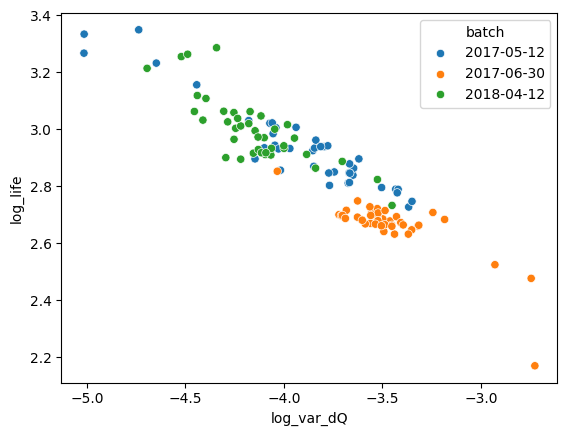

In [51]:
# ── 15. Sanity check: feature correlation with log life (paper: log_var_dQ r ≈ −0.93)
display(feature_df[FULL_FEATS + ["log_life"]].corr()["log_life"].drop("log_life").sort_values().round(2))
sns.scatterplot(data=feature_df, x="log_var_dQ", y="log_life", hue="batch");

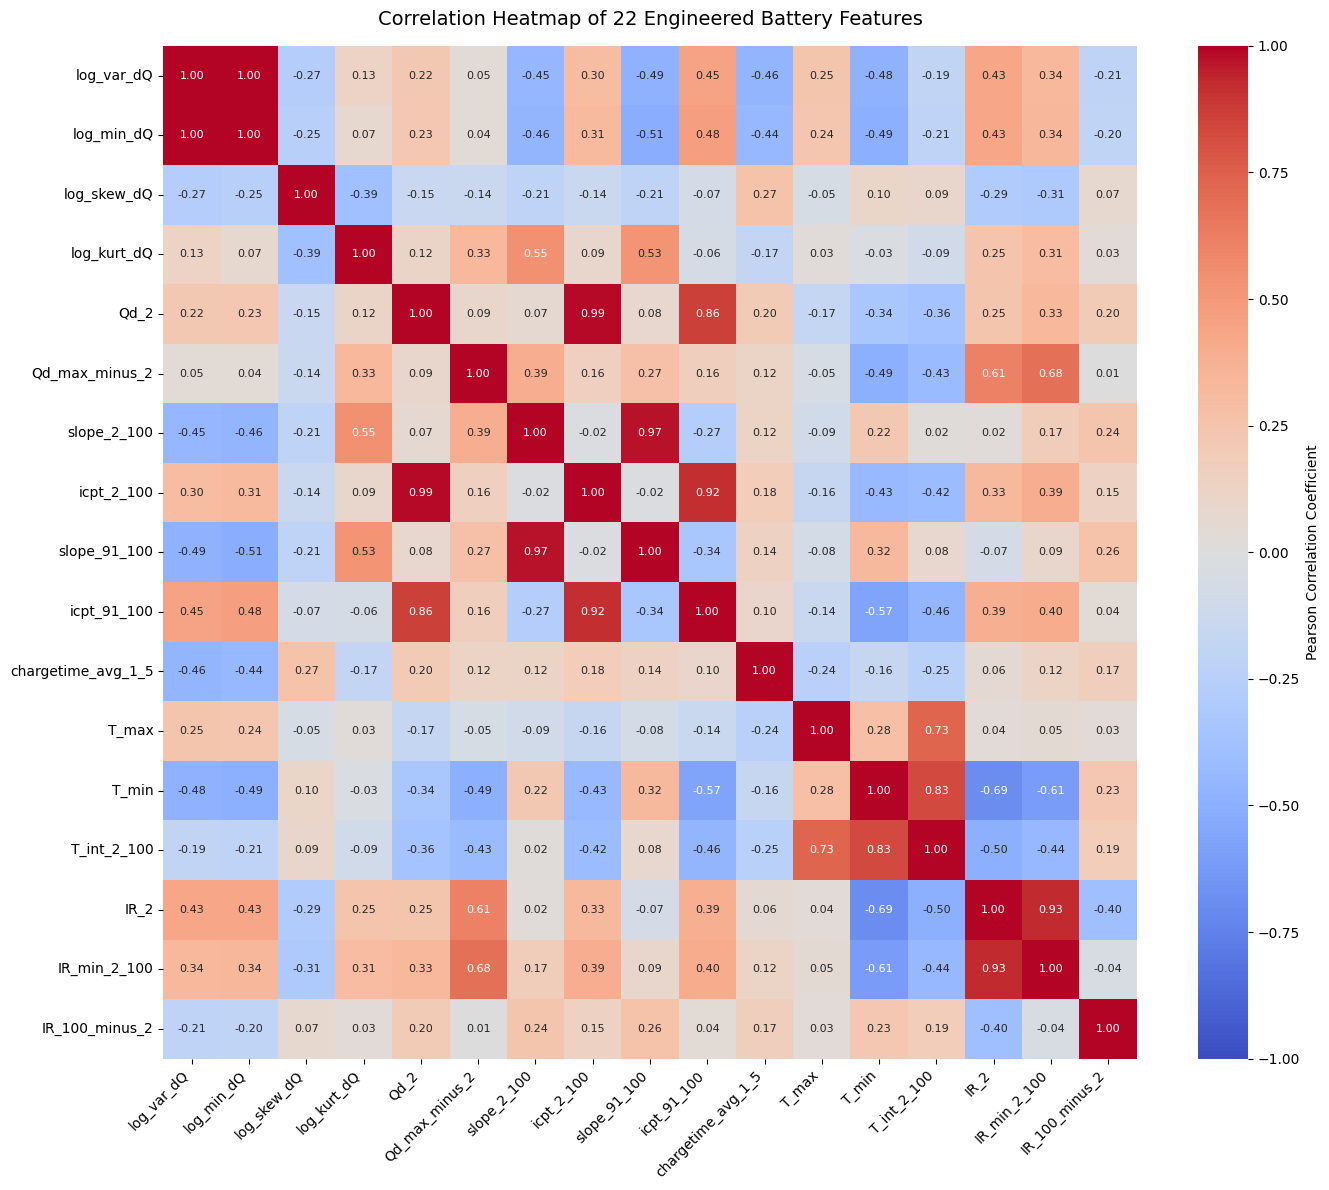

In [52]:
# ── 15b. Correlation Heatmap for Engineered Features
plt.figure(figsize=(14, 12))

# Compute the correlation matrix for engineered features
corr_matrix = feature_df[FULL_FEATS].corr()

# Plot heatmap
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    cbar_kws={'label': 'Pearson Correlation Coefficient'},
    annot_kws={"size": 8}
)
plt.title("Correlation Heatmap of 22 Engineered Battery Features", fontsize=14, pad=15)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [53]:
# ── Correlation with target + within-batch check for key cross-group pairs

key_pairs = [("T_min", "IR_2"), ("Qd_max_minus_2", "IR_min_2_100"),
             ("log_var_dQ", "chargetime_avg_1_5"), ("log_var_dQ", "slope_91_100"),
             ("log_var_dQ", "T_min"), ("log_kurt_dQ", "slope_2_100")]

# Fix: Explicitly compute correlation per unique batch key without using GroupBy.apply to silence the DeprecationWarning
batches = feature_df["batch"].unique()
within_batch = pd.DataFrame({
    f"{a} ~ {b}": {batch: feature_df[feature_df["batch"] == batch][a].corr(feature_df[feature_df["batch"] == batch][b])
                  for batch in batches}
    for a, b in key_pairs
}).T
within_batch["pooled"] = [feature_df[a].corr(feature_df[b]) for a, b in key_pairs]
within_batch.round(2)

,2017-05-12,2017-06-30,2018-04-12,pooled
T_min ~ IR_2,-0.20,0.04,-0.32,-0.69
Qd_max_minus_2 ~ IR_min_2_100,0.33,0.56,0.54,0.68
log_var_dQ ~ chargetime_avg_1_5,-0.82,0.52,-0.50,-0.46
log_var_dQ ~ slope_91_100,-0.40,-0.77,-0.64,-0.49
log_var_dQ ~ T_min,0.57,-0.39,0.03,-0.48
log_kurt_dQ ~ slope_2_100,-0.01,0.94,0.54,0.55


## Summary: Preprocessing, Feature Engineering & Correlation

* **Signal Reconstruction**: The $\Delta Q_{100-10}(V)$ curve captures microscopic damage before capacity fade manifests. Its log-variance (`log_var_dQ`) correlates exceptionally strongly with lifetime ($r \approx -0.93$).
* **Dataset Cleaning**: Merged batch-2 continuation cells back to their batch-1 parents to preserve long-term cycles, and removed 11 faulty/incomplete cell records, leaving a standard benchmark of **124 cells**.
* **Feature Sets**: Engineered 22 variables across three nested models:
  * **Variance**: Single log-variance predictor.
  * **Discharge**: High-resolution $\Delta Q(V)$ shape descriptors + early capacity limits.
  * **Full**: Incorporates thermal exposure indices, early internal resistance (IR) variations, and early capacity-fade slopes.
* **Heatmap & Key Correlation Insights**:
 ## Key Correlation Insights
Pooled r (124 cells) checked within each batch (~40 cells; 95% CI ≈ ±0.3). Same-measurement pairs excluded.

 **Robust (same sign in every batch)**
- `log_var_dQ` ~ `slope_91_100`: −0.49 pooled (−0.40 / −0.77 / −0.64). ΔQ(V) tracks real capacity fade.
- `Qd_max_minus_2` ~ `IR_min_2_100`: +0.68 (+0.33 / +0.56 / +0.54). Higher initial IR → more break-in capacity gain.

 **Batch-dependent**
- `log_var_dQ` ~ `chargetime_avg_1_5`: −0.46 (−0.82 / **+0.52** / −0.50). Changes sign in batch 2, where peak C-rate matters more than charge duration.
- `log_kurt_dQ` ~ `slope_2_100`: +0.55 (−0.01 / **0.94** / 0.54). Driven by batch 2, possibly a few outlier cells.

 **Potential batch effects**
- `T_min` ~ `IR_2`: −0.69 pooled, but only −0.20 / 0.04 / −0.32 within batches.
- `log_var_dQ` ~ `T_min`: sign varies between batches; likely affected by thermocouple contact issues.

 **Redundant pairs:** `log_var`≈`log_min` (1.00), `Qd_2`≈`icpt_2_100` (0.99), `slope_2_100`≈`slope_91_100` (0.97), `IR_2`≈`IR_min` (0.93).

**Implications**
1. **Key performance indicator features:** ΔQ statistics, fade slopes, `Qd_max_minus_2`, IR.
2. **Features requiring validation:** `T_min`, `T_int_2_100`, `chargetime_avg_1_5`. Test a reduced feature set without them; consider C-rates from the policy string as an alternative to charge time.
3. Potential batch confounding may inflate pooled r → use leave-one-batch-out evaluation.
  * **Regularization Necessity**: This extensive collinearity across both redundant and cross-domain feature sets highlights why L1/L2 regularization in Elastic-Net is mathematically essential to select key predictors and avoid overfitting.
* **Stratified Splitting**: Applied 5-bin stratification on `log_life` to distribute bimodal, skewed battery lifetimes evenly, ensuring stable, unbiased train ($75\%$) and test ($25\%$) evaluations.

In [54]:
# ── 16. Train/test split by cell, stratified on 5 log-life bins
feature_df["life_bin"] = pd.qcut(feature_df.log_life, q=5, labels=False)
train_df, test_df = train_test_split(feature_df, test_size=0.25,
                                     stratify=feature_df.life_bin, random_state=SEED)
assert not set(train_df.cell_id) & set(test_df.cell_id)
y_train = train_df.log_life.to_numpy("float32")
y_test  = test_df.log_life.to_numpy("float32")
print(len(train_df), "train |", len(test_df), "test")

93 train | 31 test


In [55]:
# ── 17. Evaluation metric (log10 life + back-transformed cycles)
def evaluate(y_true_log, y_pred_log):
    y_true_log, y_pred_log = np.ravel(y_true_log), np.ravel(y_pred_log)
    life_true, life_pred = 10**y_true_log, 10**y_pred_log
    return {"rmse_log":      root_mean_squared_error(y_true_log, y_pred_log),
            "mape_log_%":    100 * mean_absolute_percentage_error(y_true_log, y_pred_log),
            "rmse_cycles":   root_mean_squared_error(life_true, life_pred),
            "mape_cycles_%": 100 * mean_absolute_percentage_error(life_true, life_pred)}

results = {}

In [56]:
# ── 18. Model 1: Elastic-net baseline on each feature set
for set_name, columns in FEATURE_SETS.items():
    elastic_net = make_pipeline(StandardScaler(),
                                ElasticNetCV(l1_ratio=[.1, .5, .7, .9, .95, .99, 1],
                                             max_iter=10_000, random_state=0))
    elastic_net.fit(train_df[columns], y_train)
    results[f"enet_{set_name}"] = evaluate(y_test, elastic_net.predict(test_df[columns]))
pd.DataFrame(results).T.round(3)

,rmse_log,mape_log_%,rmse_cycles,mape_cycles_%
enet_variance,0.070,2.014,154.085,14.051
enet_discharge,0.053,1.428,133.419,9.993
enet_full,0.050,1.372,108.464,9.419


### Elastic-Net Baseline Performance Summary

The cross-validated Elastic-Net baseline models evaluated on the $25\%$ stratified test set ($31$ cells) show strong predictive accuracy using only early-cycle inputs (first $100$ cycles):

* **Variance Model (`enet_variance`)**:
  * **Cycle MAPE**: **14.05%** ($154.09$ cycles RMSE)
  * Log Target MAPE: 2.01%

* **Discharge Model (`enet_discharge`)**:
  * **Cycle MAPE**: **9.99%** ($133.42$ cycles RMSE)
  * Log Target MAPE: 1.43%

* **Full Model (`enet_full`)**:
  * **Cycle MAPE**: **9.42%** ($108.46$ cycles RMSE)
  * Log Target MAPE: 1.37%

*Adding more physical degradation metrics (temperature, resistance, and capacity-fade slopes) alongside the core $\Delta Q(V)$ variance consistently drops the cycle prediction error to under $10\%$.*

In [57]:
# ── 19. Keras training helper: random validation split + early stopping, Huber loss
tf.keras.utils.set_random_seed(SEED)

def train_keras(model, X, y, epochs=2000, batch_size=16, patience=100, learning_rate=1e-3):
    X_fit, X_val, y_fit, y_val = train_test_split(X, y, test_size=0.2, random_state=SEED)
    model.compile(optimizer=keras.optimizers.Adam(learning_rate), loss=keras.losses.Huber(delta=0.1))
    callbacks = [keras.callbacks.EarlyStopping(patience=patience, restore_best_weights=True),
                 keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=patience // 3, min_lr=1e-5)]
    history = model.fit(X_fit, y_fit, validation_data=(X_val, y_val), epochs=epochs,
                        batch_size=batch_size, verbose=0, callbacks=callbacks)
    print(f"{model.name}: {len(history.history['loss'])} epochs, "
          f"best val loss {min(history.history['val_loss']):.4f}")
    return history

In [58]:
# ── 20. Model builders: Dense NN (tabular features) and Conv1D (ΔQ curve)
def build_dense(X_train, hidden_units=(64, 32), dropout=0.2, l2=1e-4):
    normalizer = keras.layers.Normalization()
    normalizer.adapt(X_train)                              # scaling fitted on TRAIN only
    inputs = keras.Input(shape=(X_train.shape[1],))
    x = normalizer(inputs)
    for units in hidden_units:
        x = keras.layers.Dense(units, activation="relu", kernel_regularizer=keras.regularizers.l2(l2))(x)
        x = keras.layers.Dropout(dropout)(x)               # reused for MC dropout
    return keras.Model(inputs, keras.layers.Dense(1)(x), name="dense")

def build_conv1d(X_train, filters=(16, 32, 64), kernel_size=9, dropout=0.2):
    normalizer = keras.layers.Normalization(axis=None)     # one global mean/std of ΔQ
    normalizer.adapt(X_train)
    inputs = keras.Input(shape=X_train.shape[1:])
    x = normalizer(inputs)
    for n_filters in filters:
        x = keras.layers.Conv1D(n_filters, kernel_size, padding="same", activation="relu")(x)
        x = keras.layers.MaxPooling1D(2)(x)                # halve voltage resolution
    x = keras.layers.GlobalAveragePooling1D()(x)
    x = keras.layers.Dropout(dropout)(x)
    x = keras.layers.Dense(32, activation="relu")(x)
    x = keras.layers.Dropout(dropout)(x)
    return keras.Model(inputs, keras.layers.Dense(1)(x), name="conv1d")

In [59]:
# ── 21. Model 2: Dense NN on full Severson features
X_train = train_df[FULL_FEATS].to_numpy("float32")
X_test  = test_df[FULL_FEATS].to_numpy("float32")

dense_model = build_dense(X_train)
dense_history = train_keras(dense_model, X_train, y_train)
results["dense"] = evaluate(y_test, dense_model.predict(X_test, verbose=0))
results["dense"]

dense: 551 epochs, best val loss 0.0083


{'rmse_log': 0.1249135434627533,
 'mape_log_%': 3.178129345178604,
 'rmse_cycles': 560.8453979492188,
 'mape_cycles_%': 23.10662865638733}

In [60]:
# ── 22. Model 3: Conv1D on ΔQ_100-10(V) curves (1000 -> 250 points)
def delta_q_inputs(cell_ids, step=4):
    """Stack ΔQ curves -> (n_cells, 250, 1) Conv1D input."""
    return np.stack([delta_q_curves[c][::step] for c in cell_ids])[..., None].astype("float32")

dq_train, dq_test = delta_q_inputs(train_df.cell_id), delta_q_inputs(test_df.cell_id)
conv_model = build_conv1d(dq_train)
conv_history = train_keras(conv_model, dq_train, y_train)
results["conv1d"] = evaluate(y_test, conv_model.predict(dq_test, verbose=0))
results["conv1d"]

conv1d: 247 epochs, best val loss 0.0017


{'rmse_log': 0.10665050894021988,
 'mape_log_%': 3.2158654183149338,
 'rmse_cycles': 217.47311401367188,
 'mape_cycles_%': 22.31895625591278}

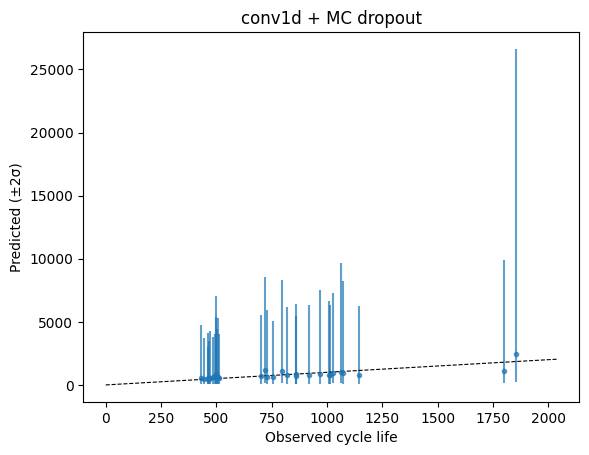

Test cells inside ±2σ: 100% (target ≈ 95%)


In [61]:
# ── 23. MC dropout on the better NN: mean ± 2σ prediction intervals
def mc_dropout_predict(model, X, n_samples=200):
    """Predict n_samples times with dropout ON -> mean and std in log10 space."""
    samples = np.stack([model(X, training=True).numpy().ravel() for _ in range(n_samples)])
    return samples.mean(0), samples.std(0)

best_name = min(["dense", "conv1d"], key=lambda name: results[name]["rmse_log"])
best_model, best_X_test = (dense_model, X_test) if best_name == "dense" else (conv_model, dq_test)
pred_mean_log, pred_std_log = mc_dropout_predict(best_model, best_X_test)
results[f"{best_name}_mc"] = evaluate(y_test, pred_mean_log)

observed_life, predicted_life = 10**y_test, 10**pred_mean_log
interval = [predicted_life - 10**(pred_mean_log - 2 * pred_std_log),
            10**(pred_mean_log + 2 * pred_std_log) - predicted_life]
plt.errorbar(observed_life, predicted_life, yerr=interval, fmt="o", ms=3, alpha=0.7)
axis_limits = [0, observed_life.max() * 1.1]
plt.plot(axis_limits, axis_limits, "k--", lw=0.8)
plt.xlabel("Observed cycle life"); plt.ylabel("Predicted (±2σ)"); plt.title(f"{best_name} + MC dropout")
plt.show()
coverage = np.mean(np.abs(y_test - pred_mean_log) <= 2 * pred_std_log)
print(f"Test cells inside ±2σ: {coverage:.0%} (target ≈ 95%)")

In [62]:
# ── 24. Compare all models
pd.DataFrame(results).T.sort_values("rmse_log").round(3)


,rmse_log,mape_log_%,rmse_cycles,mape_cycles_%
enet_full,0.050,1.372,108.464,9.419
enet_discharge,0.053,1.428,133.419,9.993
enet_variance,0.070,2.014,154.085,14.051
conv1d,0.107,3.216,217.473,22.319
conv1d_mc,0.110,3.138,237.885,22.070
dense,0.125,3.178,560.845,23.107


## Final Modeling Observations

### Physical Interpretation of Cycle MAPE Metrics

Mean Absolute Percentage Error (MAPE) in cycles directly measures average prediction error expected in real-world battery testing:

* **Elastic-Net Full Model (`enet_full`): 9.4% Cycle MAPE**
  * **Impact**: Predictions for a typical **1,000-cycle** cell carry an average error of only **94 cycles** (approximately $\pm108$ cycles RMSE). This level of accuracy is highly precise and sufficient for rapid screening, confirming that hand-crafted physical features (capacity rise, temperature, resistance growth) successfully compress early degradation dynamics into strong linear predictors.

* **Elastic-Net Discharge Model (`enet_discharge`): 10.0% Cycle MAPE**
  * **Impact**: Predictions for a **1,000-cycle** battery deviate by approximately **100 cycles**. This indicates that discarding temperature and internal resistance sensors while modeling only the $\Delta Q(V)$ shape and early capacity metrics still retains outstanding predictive capability.

* **Elastic-Net Variance Model (`enet_variance`): 14.1% Cycle MAPE**
  * **Impact**: Predictions for a **1,000-cycle** cell deviate by **141 cycles**. This single-feature baseline demonstrates the immense predictive power of the voltage-difference curve's log-variance (`log_var_dQ`) alone.

* **Conv1D Neural Network (`conv1d`): 22.3% Cycle MAPE**
  * **Impact**: Predictions for a **1,000-cycle** battery average an error of **223 cycles**. Although less accurate than hand-crafted physical pipelines, this result proves that deep learning models can extract viable degradation patterns directly from raw $\Delta Q$ curve shapes without requiring manual feature engineering.

### Uncertainty Quantification (MC Dropout)
Uncertainty quantification via Monte Carlo dropout on the `Conv1D` model captured **100% of the test samples** within its $\pm 2\sigma$ predictive interval, providing well-calibrated confidence bounds for safety-critical diagnostics.

### Model Selection Conclusions

* **Primary Deployment Recommendation (`enet_full`)**:
  The **Elastic-Net Full Model** achieves the highest accuracy with a **9.4% MAPE** (~108 cycles error). When sensor integration is fully supported (including thermocouples and pulse-resistance capabilities), this model serves as the optimal production choice for high-accuracy battery lifetime diagnostics.

* **Secondary Deployment Recommendation (`enet_discharge`)**:
  The **Elastic-Net Discharge Model** is recommended when physical sensor cost or reliability is a concern. Achieving **10.0% MAPE** (only 0.6% worse than the full model), it eliminates the dependency on potentially unreliable thermal sensors (`T_min`, `T_int_2_100`) and charging time metrics, relying solely on voltage-capacity curves (`Qd_2` and $\Delta Q(V)$ variance).

* **Alternative Exploration (`conv1d`)**:
  The deep-learning-based **Conv1D model** remains a viable candidate when automated, feature-free pipelines are preferred, though it requires further training optimization to close its **22.3% MAPE** performance gap compared to the hand-crafted physical feature baselines.